# Разведочный анализ MTS-Dialog

Анализ выполнен на приложенном файле **MTS-Dialog-TrainingSet.csv**, официальной обучающей выборке. Одна строка соответствует паре из диалога и эталонного раздела клинической заметки. В официальном наборе также есть validation и два test-сплита. Все статистики и графики ниже относятся к train.

- [Репозиторий MTS-Dialog и описание разбиения](https://github.com/abachaa/MTS-Dialog)
- [Ben Abacha et al., EACL 2023, *An Empirical Study of Clinical Note Generation from Doctor-Patient Encounters*](https://aclanthology.org/2023.eacl-main.168/)

Для повторного запуска положите CSV рядом с ноутбуком или в подпапку `upload`. В Google Colab загрузите CSV в рабочую папку сессии. Зависимости Python — `pandas`, `numpy`, `matplotlib` (≥ 3.6), `seaborn` (≥ 0.13), `scipy` (≥ 1.10) и `IPython`.

## Импорты

In [1]:
from collections import Counter
from pathlib import Path
import re

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy import stats

pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 80)
sns.set_theme(style="whitegrid", palette="pastel", font="DejaVu Sans")
random_state = 42

## Первый взгляд на данные

| Поле | Содержание |
|---|---|
| `ID` | Идентификатор строки |
| `section_header` | Категория раздела клинической заметки |
| `section_text` | Эталонный текст раздела |
| `dialogue` | Диалог с метками участников |

В предпросмотре длинные тексты сокращены. При чтении CSV сохраняем текстовые значения в исходном виде и отдельно считаем пустые строки.

In [2]:
filename = "MTS-Dialog-TrainingSet.csv"
candidates = [Path(filename), Path("upload") / filename]
csv_path = next((path for path in candidates if path.is_file()), None)
if csv_path is None:
    raise FileNotFoundError(f"Поместите {filename} рядом с ноутбуком или в папку upload.")

df = pd.read_csv(csv_path, encoding="utf-8-sig", keep_default_na=False)
target = "section_header"
text_cols = ["section_text", "dialogue"]
print(f"Размер выборки — {df.shape[0]:,} строк и {df.shape[1]} столбца".replace(",", " "))

preview = df.head().copy()
for col in text_cols:
    excerpt = preview[col].str.replace(r"\s+", " ", regex=True)
    preview[col] = excerpt.where(excerpt.str.len() <= 72, excerpt.str.slice(0, 71) + "…")
preview

Размер выборки — 1 201 строк и 4 столбца


,ID,section_header,section_text,dialogue
0,0,GENHX,The patient is a 76-year-old white female who presents to the clinic to…,"Doctor: What brings you back into the clinic today, miss? Patient: I ca…"
1,1,GENHX,The patient is a 25-year-old right-handed Caucasian female who presente…,Doctor: How're you feeling today? Patient: Terrible. I'm having the wor…
2,2,GENHX,"This is a 22-year-old female, who presented to the office complaining o…","Doctor: Hello, miss. What is the reason for your visit today? Patient: …"
3,3,MEDICATIONS,"Prescribed medications were Salmeterol inhaler, prn; and Fluticasone na…","Doctor: Are you taking any over the counter medicines? Patient: No, onl…"
4,4,CC,"Burn, right arm.","Doctor: Hi, how are you? Patient: I burned my hand. Doctor: Oh, I am so…"


In [3]:
field_summary = pd.DataFrame({
    "Тип": df.dtypes.astype(str),
    "Уникальных значений": df.nunique(),
    "Пропуски": df.isna().sum(),
    "Пропуски, %": df.isna().mean().mul(100),
    "Пустые или пробельные строки": [
        df[col].str.fullmatch(r"\s*", na=False).sum() if col != "ID" else df[col].eq("").sum()
        for col in df
    ],
})
display(field_summary)
display(df[[target] + text_cols].describe().drop(index="top"))

,Тип,Уникальных значений,Пропуски,"Пропуски, %",Пустые или пробельные строки
ID,int64,1201,0,0.0,0
section_header,object,20,0,0.0,0
section_text,object,1071,0,0.0,0
dialogue,object,1199,0,0.0,0


,section_header,section_text,dialogue
count,1201,1201,1201
unique,20,1071,1199
freq,351,37,2


In [4]:
pd.Series({
    "Полные дубликаты": df.duplicated().sum(),
    "Дубликаты без ID": df.drop(columns="ID").duplicated().sum(),
    "Повторные ID": df["ID"].duplicated().sum(),
    "Повторные диалоги": df["dialogue"].duplicated().sum(),
    "Повторные тексты заметок": df["section_text"].duplicated().sum(),
}, name="Повторных строк после первого вхождения").to_frame()

,Повторных строк после первого вхождения
Полные дубликаты,0
Дубликаты без ID,1
Повторные ID,0
Повторные диалоги,2
Повторные тексты заметок,130


Пропусков и пустых текстов нет. Все ID уникальны. Есть одна дублирующая строка без учёта ID и два повторных вхождения диалогов. Подробнее о них — в разделе проверки качества.

## Начало анализа

`section_header` — целевая переменная в задаче классификации раздела. В задаче суммаризации `dialogue` служит входом, а `section_text` — эталонным текстом. Признаки, рассчитанные по `section_text`, здесь используются для описания корпуса.

In [5]:
counts = df[target].value_counts()
order = counts.index.tolist()
shares = counts.div(len(df)).mul(100)
class_summary = pd.DataFrame({
    "Количество": counts,
    "Доля, %": shares,
    "Накопленная доля, %": shares.cumsum(),
})
class_summary.round(2)

,Количество,"Доля, %","Накопленная доля, %"
section_header,,,
FAM/SOCHX,351,29.23,29.23
GENHX,282,23.48,52.71
PASTMEDICALHX,118,9.83,62.53
CC,77,6.41,68.94
PASTSURGICAL,63,5.25,74.19
ALLERGY,60,5.00,79.18
ROS,60,5.00,84.18
MEDICATIONS,54,4.50,88.68
ASSESSMENT,34,2.83,91.51


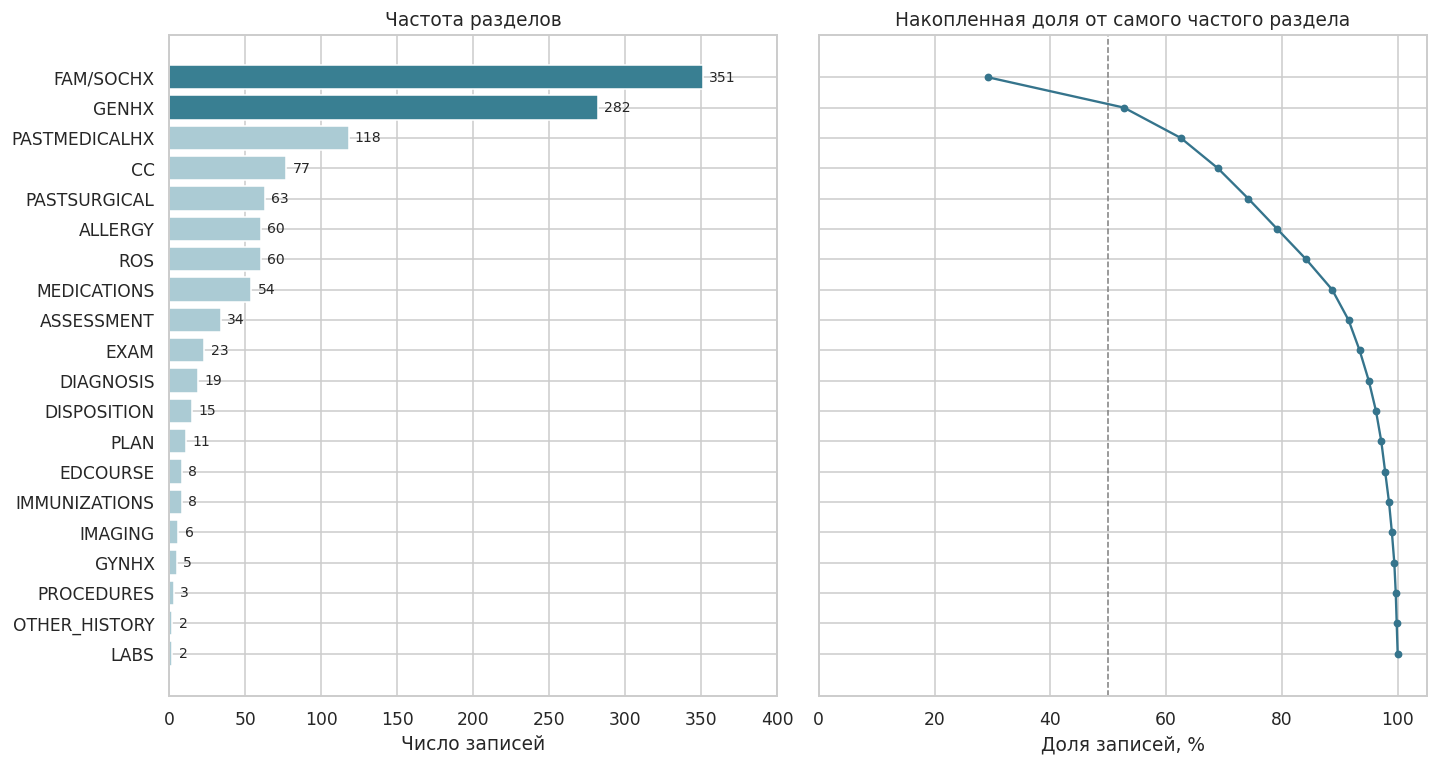

In [6]:
fig, (ax_count, ax_share) = plt.subplots(ncols=2, figsize=(13, 7), sharey=True)
positions = np.arange(len(order))
colors = ["#397F92" if i < 2 else "#ABCBD4" for i in positions]
bars = ax_count.barh(positions, counts, color=colors)
ax_count.bar_label(bars, padding=4, fontsize=9)
ax_count.set(yticks=positions, yticklabels=order, xlabel="Число записей",
             title="Частота разделов", xlim=(0, counts.max() * 1.14))
ax_count.invert_yaxis()

ax_share.plot(shares.cumsum(), positions, "o-", color="#35748C", markersize=4)
ax_share.axvline(50, color="#808080", ls="--", lw=1)
ax_share.set(xlim=(0, 105), xlabel="Доля записей, %",
             title="Накопленная доля от самого частого раздела")
ax_share.xaxis.set_major_locator(mticker.MultipleLocator(20))
fig.tight_layout()
plt.show()

Два крупнейших раздела, `FAM/SOCHX` (семейный и социальный анамнез) и `GENHX` (анамнез текущего заболевания), составляют **52,7%** выборки. У семи классов меньше 10 записей, а у `LABS` и `OTHER_HISTORY` — по две.

### Числовые признаки

- Длину диалога считаем по тексту реплик без меток участников. Длину заметки считаем по `section_text`. Одно слово — последовательность букв или цифр, допускающая внутренний дефис или апостроф.
- Реплика — непустая строка с распознанной меткой участника. Строки без метки учитываем при подсчёте слов. Варианты меток приводим к четырём группам только при расчёте признаков.
- Относительная длина заметки — число слов в заметке, делённое на число слов в диалоге и умноженное на 100.
- Лексическое совпадение — доля токенов заметки, совпавших с токенами диалога без учёта регистра. Кратность совпадений ограничена числом вхождений в диалоге. Метрика описывает поверхностное совпадение слов.

In [7]:
role_aliases = {
    "Doctor": "Врач",
    "Doctor_2": "Врач",
    "Docotr_2": "Врач",
    "Patient": "Пациент",
    "Guest_family": "Семья",
    "Guest_family_1": "Семья",
    "Guest_family_2": "Семья",
    "Guest_family2": "Семья",
    "Gest_family": "Семья",
    "Guest_clinician": "Приглашённый медработник",
    "Guest_clinican": "Приглашённый медработник",
}
role_pattern = re.compile(
    r"^\s*(?:(?P<role>[\w]+)\s*:|(?P<family>Guest_family)\.)\s*(?P<body>.*)$"
)
word_pattern = re.compile(r"[^\W_]+(?:[’'-][^\W_]+)*")

def words(text):
    return word_pattern.findall(text.casefold())

def parse_dialogue(text):
    raw_roles, bodies, unmarked_lines = [], [], []
    for line in text.splitlines():
        if not line.strip():
            continue
        match = role_pattern.fullmatch(line)
        if match:
            raw_roles.append(match["role"] or match["family"])
            bodies.append(match["body"])
        else:
            unmarked_lines.append(line.strip())
            bodies.append(line)
    return raw_roles, words(" ".join(bodies)), unmarked_lines

parsed = df["dialogue"].map(parse_dialogue)
raw_roles = parsed.map(lambda parts: parts[0])
roles = raw_roles.map(lambda labels: [role_aliases.get(label, "Другая роль") for label in labels])
dialogue_words = parsed.map(lambda parts: parts[1])
note_words = df["section_text"].map(words)

data = df[[target]].copy()
data["Слов в диалоге"] = dialogue_words.str.len()
data["Слов в заметке"] = note_words.str.len()
data["Реплик"] = roles.str.len()
data["Длина заметки, %"] = data["Слов в заметке"].div(
    data["Слов в диалоге"].replace(0, np.nan)
).mul(100)
matched_words = pd.Series([
    sum((Counter(note) & Counter(dialogue)).values())
    for note, dialogue in zip(note_words, dialogue_words)
], index=df.index)
data["Совпадение слов, %"] = matched_words.div(data["Слов в заметке"].replace(0, np.nan)).mul(100)
numeric_cols = data.columns.drop(target).tolist()

data["Участие семьи"] = np.where(roles.map(lambda labels: "Семья" in labels), "Да", "Нет")
data["Участие медработника"] = np.where(
    roles.map(lambda labels: "Приглашённый медработник" in labels), "Да", "Нет"
)
data["Первая реплика"] = roles.str[0].fillna("Без метки")
category_cols = ["Участие семьи", "Участие медработника", "Первая реплика"]

In [8]:
numeric = data[numeric_cols]
summary = numeric.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).T
summary = summary.assign(Асимметрия=numeric.skew()).rename(columns={
    "count": "n", "mean": "Среднее", "std": "Ст. откл.", "min": "Мин.",
    "50%": "Медиана", "max": "Макс.",
})
summary.round(2)

,n,Среднее,Ст. откл.,Мин.,5%,25%,Медиана,75%,95%,Макс.,Асимметрия
Слов в диалоге,1201.0,96.16,109.43,4.00,11.00,29.00,56.00,121.00,310.00,1415.00,3.37
Слов в заметке,1201.0,40.92,67.41,1.00,1.00,5.00,14.00,46.00,151.00,1027.00,4.73
Реплик,1201.0,9.54,8.81,1.00,2.00,4.00,6.00,12.00,25.00,94.00,2.83
"Длина заметки, %",1201.0,34.18,23.80,0.89,3.98,14.58,31.43,48.92,76.19,167.68,0.96
"Совпадение слов, %",1201.0,45.47,25.22,0.00,0.00,33.33,47.89,59.26,100.00,100.00,-0.03


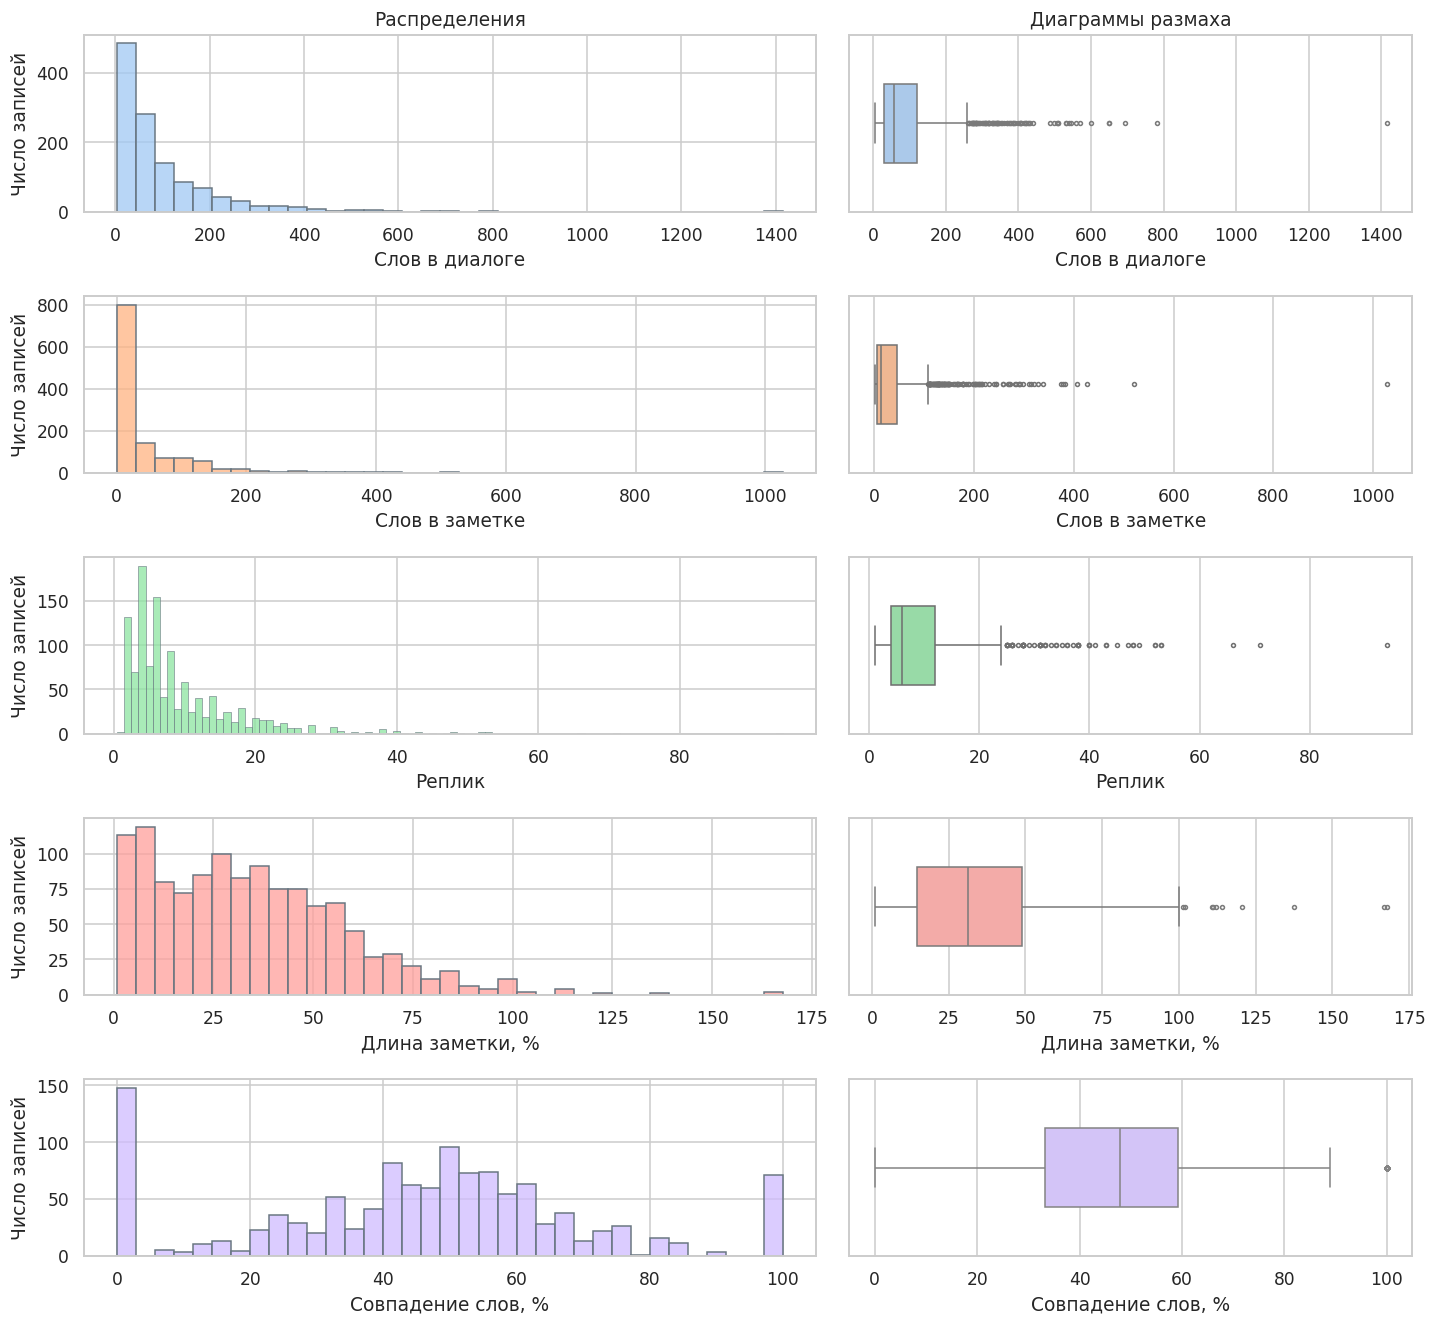

In [9]:
fig, axes = plt.subplots(len(numeric_cols), 2, figsize=(13, 12),
                         gridspec_kw={"width_ratios": [1.3, 1]})
for feature, (ax_hist, ax_box), color in zip(numeric_cols, axes, sns.color_palette("pastel", 5)):
    values = data[feature]
    discrete = feature == "Реплик"
    sns.histplot(x=values, bins=35, discrete=discrete, ax=ax_hist, color=color, edgecolor="#687681")
    sns.boxplot(x=values, ax=ax_box, color=color, width=0.45, fliersize=2.5)
    ax_hist.set_ylabel("Число записей")
    ax_box.set_yticks([])
axes[0, 0].set_title("Распределения")
axes[0, 1].set_title("Диаграммы размаха")
fig.tight_layout(h_pad=1.4)
plt.show()

Медианы по всему train — **56 слов в диалоге, 14 слов в заметке и 6 реплик**. Длины имеют выраженный правый хвост. Медианное отношение длин по отдельным парам — 31,4%. В десяти парах заметка длиннее диалога.

### Категориальные признаки

Для признаков состава участников считаем частоты по диалогам. «Участие медработника» обозначает реплику участника с меткой группы `Guest_clinician`. Метка врача учитывается отдельно.

In [10]:
category_distributions = {}
for feature in category_cols:
    frequency = data[feature].value_counts()
    category_distributions[feature] = pd.DataFrame({
        "Количество": frequency,
        "Доля, %": frequency.div(len(data)).mul(100),
    })

pd.concat(category_distributions, names=["Признак", "Значение"]).round(2)

Количество  Доля, %
Признак              Значение                                     
Участие семьи        Нет                             1074    89.43
                     Да                               127    10.57
Участие медработника Нет                             1149    95.67
                     Да                                52     4.33
Первая реплика       Врач                            1143    95.17
                     Пациент                           24     2.00
                     Приглашённый медработник          21     1.75
                     Семья                             13     1.08

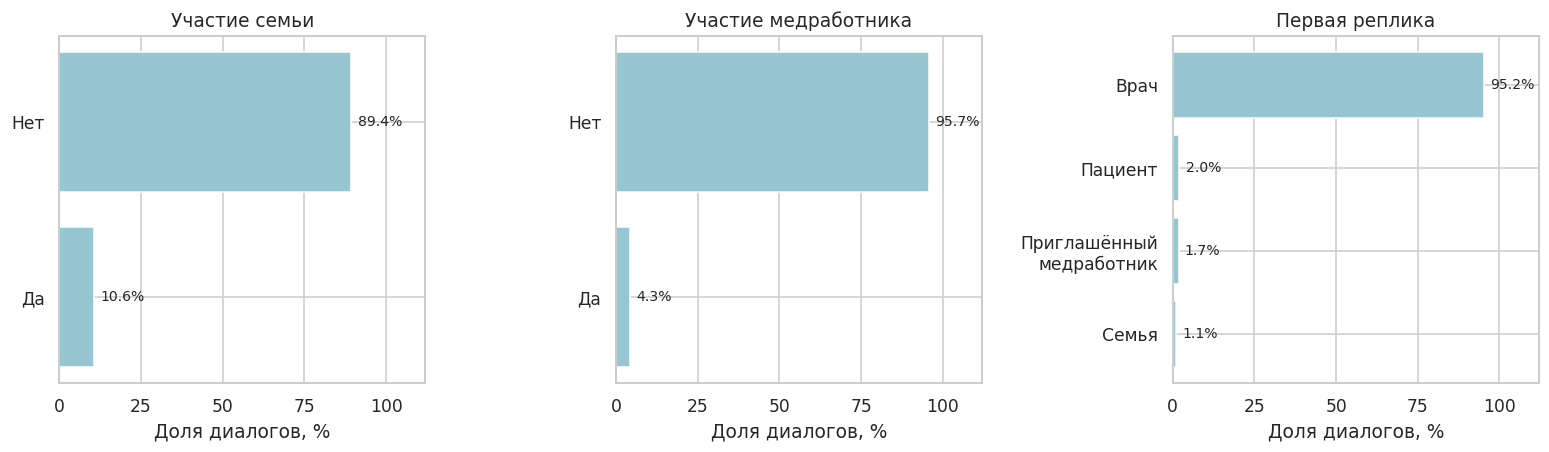

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharex=True)
for ax, (feature, distribution) in zip(axes, category_distributions.items()):
    positions = np.arange(len(distribution))
    bars = ax.barh(positions, distribution["Доля, %"], color="#96C6D2")
    ax.bar_label(bars, labels=[f"{share:.1f}%" for share in distribution["Доля, %"]],
                 padding=4, fontsize=9)
    labels = distribution.index.str.replace("Приглашённый медработник",
                                            "Приглашённый\nмедработник", regex=False)
    ax.set(yticks=positions, yticklabels=labels, xlim=(0, 112),
           title=feature, xlabel="Доля диалогов, %")
    ax.invert_yaxis()
    ax.xaxis.set_major_locator(mticker.MultipleLocator(25))
fig.tight_layout(w_pad=2.0)
plt.show()

## Проверка качества данных

Для поиска повторов применяем нормализацию Unicode NFKC, приводим регистр и пробелы к единому виду. Редкими считаем классы с числом записей меньше десяти. Верхний выброс — значение выше третьего квартиля плюс 1,5 межквартильного размаха. В расчёты включаем повторы и длинные тексты.

In [12]:
normalized = df[[target] + text_cols].apply(
    lambda col: col.str.normalize("NFKC").str.casefold().str.split().str.join(" ")
)
same_dialogue = normalized.groupby("dialogue").agg(
    n=(target, "size"), headers=(target, "nunique"), notes=("section_text", "nunique")
)
unmarked = parsed.map(lambda parts: parts[2])
raw_label_counts = Counter(label for labels in raw_roles for label in labels)
q1, q3 = numeric.quantile(0.25), numeric.quantile(0.75)
upper_fence = q3 + 1.5 * (q3 - q1)
upper_outliers = numeric.gt(upper_fence).sum()

quality = pd.Series({
    "Дубликаты без ID после нормализации": normalized.duplicated().sum(),
    "Группы одинаковых диалогов": same_dialogue["n"].gt(1).sum(),
    "Одинаковый диалог с разными разделами": same_dialogue["headers"].gt(1).sum(),
    "Одинаковый диалог с разными текстами заметки": same_dialogue["notes"].gt(1).sum(),
    "Классы с числом записей < 10": counts.lt(10).sum(),
    "Строки в классах с числом записей < 10": counts[counts.lt(10)].sum(),
    "Диалоги без распознанных реплик": data["Реплик"].eq(0).sum(),
    "Непустые строки диалогов без распознанной метки": unmarked.str.len().sum(),
    "Диалоги с меткой Guest_family и точкой вместо двоеточия":
        df["dialogue"].str.contains(r"(?m)^\s*Guest_family\.").sum(),
    "Нераспознанные варианты меток с двоеточием":
        sum(n for label, n in raw_label_counts.items() if label not in role_aliases),
    "Заметки длиннее диалога": data["Длина заметки, %"].gt(100).sum(),
    "Верхние выбросы по длине диалога": upper_outliers["Слов в диалоге"],
    "Верхние выбросы по длине заметки": upper_outliers["Слов в заметке"],
}, name="Количество").to_frame()
quality

,Количество
Дубликаты без ID после нормализации,1
Группы одинаковых диалогов,2
Одинаковый диалог с разными разделами,0
Одинаковый диалог с разными текстами заметки,1
Классы с числом записей < 10,7
Строки в классах с числом записей < 10,34
Диалоги без распознанных реплик,0
Непустые строки диалогов без распознанной метки,1
Диалоги с меткой Guest_family и точкой вместо двоеточия,1
Нераспознанные варианты меток с двоеточием,0


In [13]:
repeat_mask = normalized.duplicated("dialogue", keep=False)
repeat_df = df.loc[repeat_mask, ["ID", target]].copy()
repeat_df["Группа диалогов"] = pd.factorize(normalized.loc[repeat_mask, "dialogue"])[0] + 1
repeat_df["Вариант заметки"] = (
    normalized.loc[repeat_mask]
    .groupby("dialogue")["section_text"]
    .transform(lambda values: pd.factorize(values)[0] + 1)
)
display(repeat_df.sort_values(["Группа диалогов", "ID"]).reset_index(drop=True))

label_audit = pd.Series(raw_label_counts, name="Реплик").sort_values(ascending=False).to_frame()
label_audit["Группа"] = label_audit.index.map(role_aliases)
display(label_audit)

,ID,section_header,Группа диалогов,Вариант заметки
0,256,FAM/SOCHX,1,1
1,1109,FAM/SOCHX,1,1
2,901,ALLERGY,2,1
3,989,ALLERGY,2,2


,Реплик,Группа
Doctor,5807,Врач
Patient,4894,Пациент
Guest_family,560,Семья
Guest_clinician,119,Приглашённый медработник
Doctor_2,43,Врач
Guest_family_1,16,Семья
Guest_family_2,9,Семья
Guest_clinican,2,Приглашённый медработник
Guest_family2,1,Семья
Gest_family,1,Семья


Пары ID **256 и 1109** содержат одинаковый диалог и одинаковую заметку. У ID **901 и 989** одинаковый диалог и класс `ALLERGY`, а тексты заметок различаются. Если создавать собственное разбиение train, одинаковые диалоги стоит держать в одном сплите.

## Корреляции признаков

Сравниваем корреляции Пирсона и Спирмена между числовыми признаками. `section_header` имеет номинальные категории, поэтому числовые связи с ним рассматриваем через группировки ниже. Относительная длина заметки вычисляется из двух длин, поэтому эти корреляции частично заданы формулой признака.

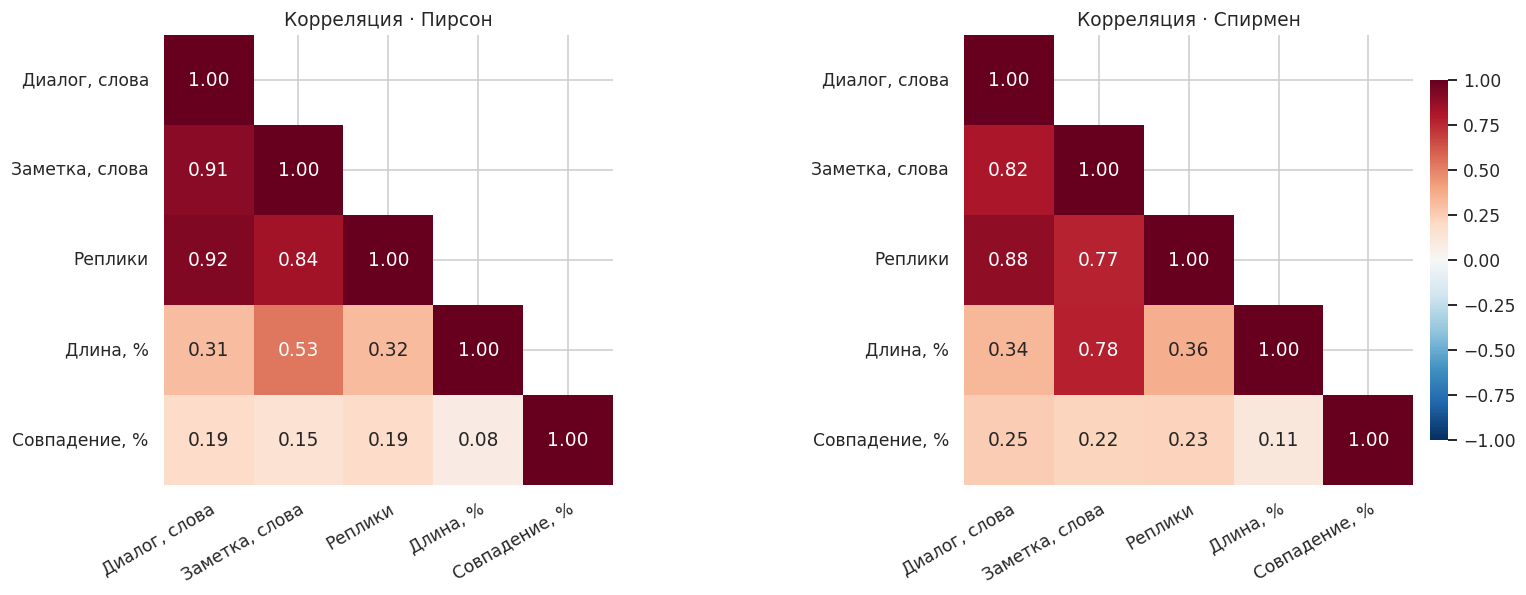

In [14]:
short_names = {
    "Слов в диалоге": "Диалог, слова",
    "Слов в заметке": "Заметка, слова",
    "Реплик": "Реплики",
    "Длина заметки, %": "Длина, %",
    "Совпадение слов, %": "Совпадение, %",
}
correlations = {}
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2), layout="constrained")
for ax, (method, title) in zip(axes, [("pearson", "Пирсон"), ("spearman", "Спирмен")]):
    corr = numeric.corr(method=method)
    correlations[method] = corr
    matrix = corr.rename(index=short_names, columns=short_names)
    sns.heatmap(matrix, mask=np.triu(np.ones_like(matrix, dtype=bool), k=1),
                cmap="RdBu_r", vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
                square=True, cbar=(method == "spearman"), ax=ax,
                cbar_kws={"shrink": 0.8, "pad": 0.025})
    ax.set_title(f"Корреляция · {title}")
    ax.tick_params(axis="x", rotation=30)
    ax.tick_params(axis="y", rotation=0)
    plt.setp(ax.get_xticklabels(), ha="right", rotation_mode="anchor")
plt.show()

In [15]:
pairs = np.triu_indices(len(numeric_cols), k=1)
pair_summary = pd.DataFrame({
    "Признак 1": np.asarray(numeric_cols)[pairs[0]],
    "Признак 2": np.asarray(numeric_cols)[pairs[1]],
    "Пирсон": correlations["pearson"].to_numpy()[pairs],
    "Спирмен": correlations["spearman"].to_numpy()[pairs],
})
pair_summary.sort_values("Спирмен", key=lambda values: values.abs(), ascending=False).round(3)

,Признак 1,Признак 2,Пирсон,Спирмен
1,Слов в диалоге,Реплик,0.925,0.884
0,Слов в диалоге,Слов в заметке,0.905,0.819
5,Слов в заметке,"Длина заметки, %",0.533,0.781
4,Слов в заметке,Реплик,0.840,0.773
7,Реплик,"Длина заметки, %",0.315,0.361
2,Слов в диалоге,"Длина заметки, %",0.309,0.336
3,Слов в диалоге,"Совпадение слов, %",0.194,0.250
8,Реплик,"Совпадение слов, %",0.188,0.229
6,Слов в заметке,"Совпадение слов, %",0.149,0.224
9,"Длина заметки, %","Совпадение слов, %",0.082,0.111


С ростом длины диалога обычно растёт и длина заметки (Пирсон **0,905**, Спирмен **0,819**). Длина диалога тесно связана с числом реплик (Спирмен **0,884**). У лексического совпадения связь с остальными метриками заметно слабее (Спирмен от **0,111** до **0,250**).

## Числовые признаки и раздел заметки

В таблице представлены средние и медианы для всех классов. На диаграммах длины показаны в логарифмическом масштабе. Точки за пределами «усов» отображены, у малых классов весь диапазон может определяться несколькими наблюдениями.

In [16]:
by_section = data.groupby(target, observed=True)
section_numeric = by_section[numeric_cols].agg(["mean", "median"]).reindex(order)
section_numeric = section_numeric.rename(columns={"mean": "среднее", "median": "медиана"})
section_numeric.insert(0, ("Размер", "n"), counts)
section_numeric.round(2)

Размер Слов в диалоге         Слов в заметке          Реплик  \
                    n        среднее медиана        среднее медиана среднее   
section_header                                                                
FAM/SOCHX         351          62.38    51.0          20.62    14.0    7.07   
GENHX             282         223.96   195.5         119.10   102.0   19.26   
PASTMEDICALHX     118          62.86    47.5          19.03    10.0    6.72   
CC                 77          59.12    40.0           7.96     5.0    6.74   
PASTSURGICAL       63          45.76    36.0           9.86     6.0    5.06   
ALLERGY            60          21.08    15.0           4.17     4.0    3.67   
ROS                60          74.80    51.0          30.35    21.5   10.88   
MEDICATIONS        54          34.69    23.5           8.72     4.5    4.57   
ASSESSMENT         34          71.71    47.5          19.65     9.0    6.50   
EXAM               23          58.70    48.0          15.48    15.0    6.70   
DIAGNOSIS          19          59.84    48.0           7.79     7.0    5.84   
DISPOSITION        15          30.33    19.0           8.93     3.0    3.93   
PLAN               11          62.82    47.0          25.73     8.0    5.64   
EDCOURSE            8          67.00    52.0          51.00    29.5    6.12   
IMMUNIZATIONS       8          40.88    22.0           6.75     1.5    4.38   
IMAGING             6          49.33    48.5          15.50    10.0    3.50   
GYNHX               5          83.00    64.0          18.40     9.0    8.60   
PROCEDURES          3          44.00    13.0           1.33     1.0    5.67   
OTHER_HISTORY       2          52.00    52.0          12.00    12.0    5.00   
LABS                2          36.00    36.0          18.00    18.0    3.00   

                       Длина заметки, %         Совпадение слов, %          
               медиана          среднее медиана            среднее медиана  
section_header                                                              
FAM/SOCHX          6.0            31.90   30.30              38.10   41.67  
GENHX             18.0            52.61   50.29              50.91   51.52  
PASTMEDICALHX      6.0            26.68   23.58              43.18   45.35  
CC                 6.0            15.10    9.68              56.49   57.14  
PASTSURGICAL       4.0            20.21   18.52              45.66   45.71  
ALLERGY            3.5            27.24   21.05              50.56   50.00  
ROS                8.0            44.73   40.59              47.00   50.00  
MEDICATIONS        4.0            24.12   18.75              50.88   52.27  
ASSESSMENT         6.0            27.05   25.00              47.84   47.76  
EXAM               6.0            33.57   26.98              47.02   45.45  
DIAGNOSIS          5.0            20.59   10.14              58.26   66.67  
DISPOSITION        4.0            24.53   18.92              45.72   33.33  
PLAN               5.0            30.14   19.15              48.02   50.00  
EDCOURSE           5.0            57.61   63.59              34.89   35.90  
IMMUNIZATIONS      3.5             9.63    6.35               6.25    0.00  
IMAGING            3.5            34.65   31.63              34.35   32.14  
GYNHX              8.0            22.57   15.25              28.40   30.77  
PROCEDURES         2.0             6.87    7.69              16.67    0.00  
OTHER_HISTORY      5.0            23.51   23.51              29.29   29.29  
LABS               3.0            53.90   53.90              70.62   70.62

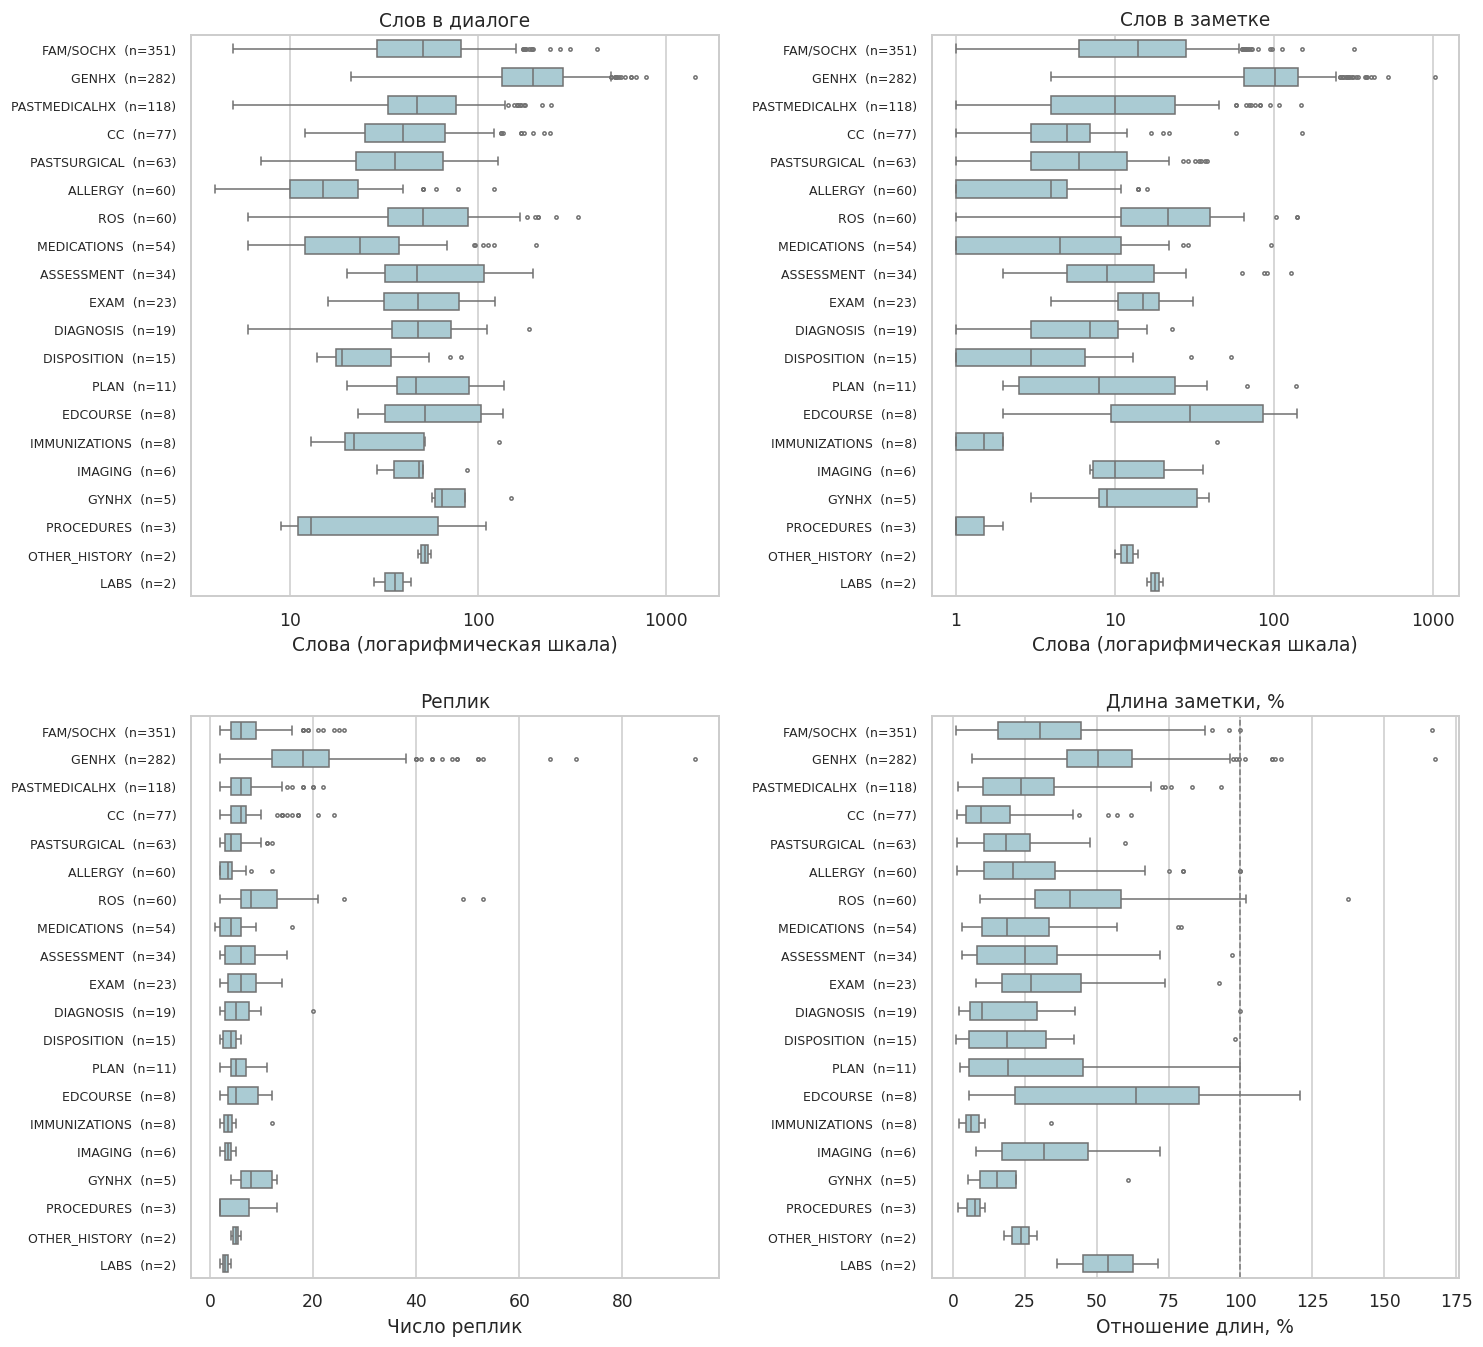

In [17]:
labels = [f"{label}  (n={counts[label]})" for label in order]
features = ["Слов в диалоге", "Слов в заметке", "Реплик", "Длина заметки, %"]
fig, axes = plt.subplots(2, 2, figsize=(13.4, 12.2))
for ax, feature in zip(axes.flat, features):
    sns.boxplot(data=data, x=feature, y=target, order=order, ax=ax,
                color="#A3CFDA", fliersize=2.1, width=0.62)
    ax.set(title=feature, xlabel="", ylabel="")
    ax.set_yticks(range(len(order)), labels, fontsize=8)
    if feature in ["Слов в диалоге", "Слов в заметке"]:
        ax.set_xscale("log")
        ax.xaxis.set_major_formatter(mticker.ScalarFormatter())
        ax.set_xlabel("Слова (логарифмическая шкала)")
    elif feature == "Длина заметки, %":
        ax.axvline(100, color="#7A7A7A", ls="--", lw=1)
        ax.set_xlabel("Отношение длин, %")
    else:
        ax.set_xlabel("Число реплик")
fig.tight_layout(h_pad=2, w_pad=1.8)
plt.show()

В `GENHX` медиана длины диалога — **195,5 слова**, а заметки — **102 слова**. В `ALLERGY` соответствующие медианы — **15 и 4 слова**. Группы различаются и по тому, какую долю длины диалога занимает заметка. Например, медиана в `GENHX` — **50,3%**, в `CC` — **9,7%**.

## Категориальные признаки и раздел заметки

Сравниваем доли по каждому классу. Для бинарных признаков показываем долю ответа «Да», для первой реплики — долю диалогов, начатых врачом. Усы показывают 95% интервалы Уилсона для каждой доли. В таблицах сопряжённости используем все значения каждого признака, включая все четыре варианта первой реплики.

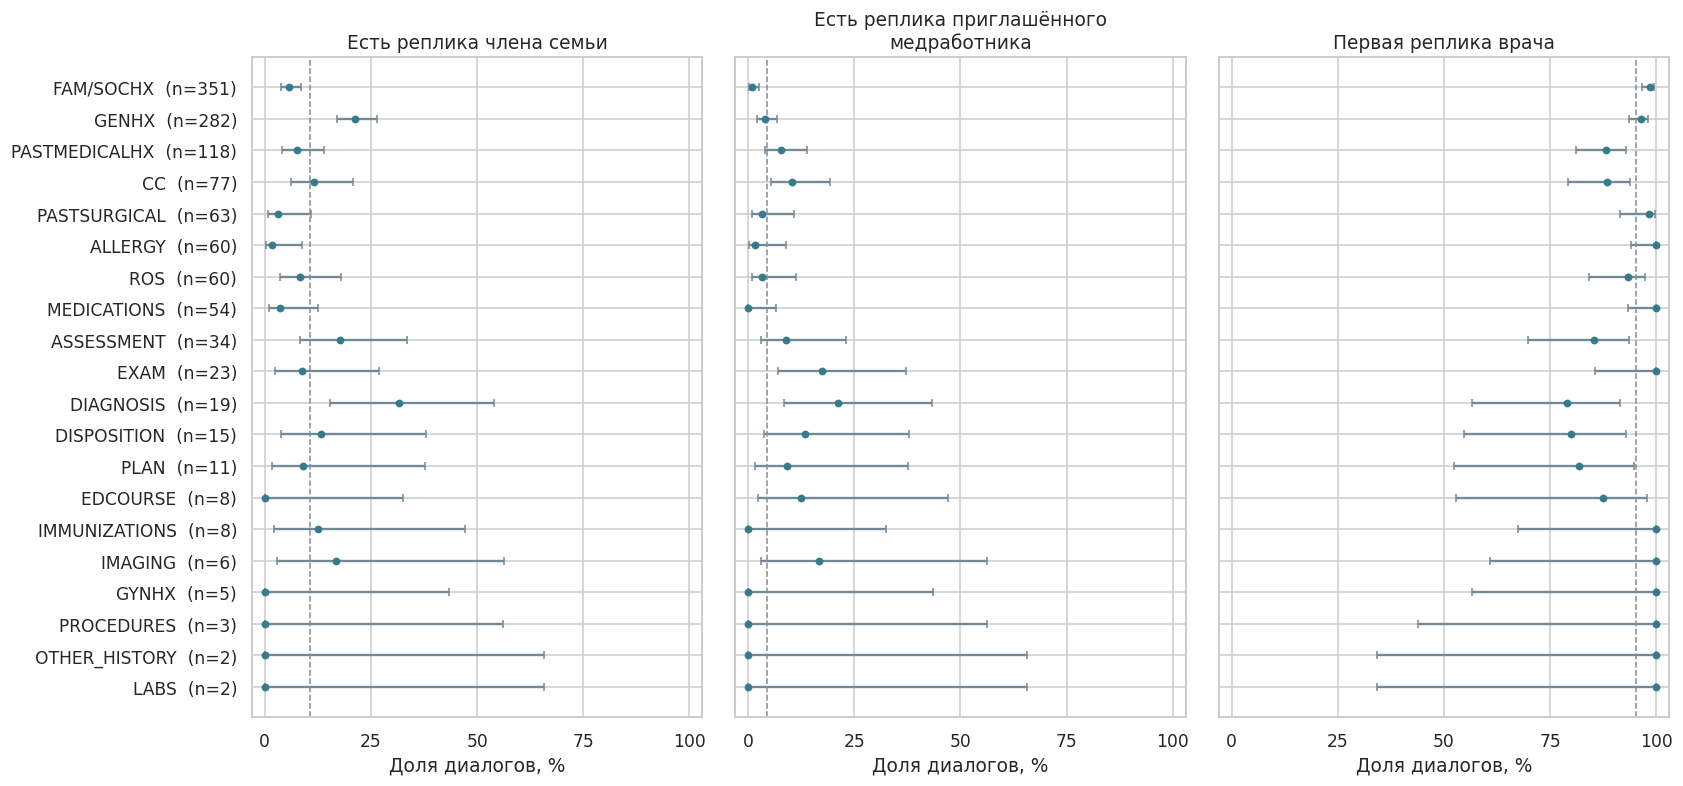

In [18]:
events = {
    "Есть реплика члена семьи": data["Участие семьи"].eq("Да"),
    "Есть реплика приглашённого медработника": data["Участие медработника"].eq("Да"),
    "Первая реплика врача": data["Первая реплика"].eq("Врач"),
}
z = stats.norm.ppf(0.975)
wilson_tables = {}
fig, axes = plt.subplots(1, 3, figsize=(15.2, 7.2), sharey=True)
positions = np.arange(len(order))

for ax, (name, event) in zip(axes, events.items()):
    successes = event.groupby(data[target]).sum().reindex(order)
    rate = successes / counts
    denominator = 1 + z**2 / counts
    center = (rate + z**2 / (2 * counts)) / denominator
    half = z * np.sqrt(rate * (1 - rate) / counts + z**2 / (4 * counts**2)) / denominator
    lower = (center - half).clip(0, 1)
    upper = (center + half).clip(0, 1)
    wilson_tables[name] = pd.DataFrame({
        "n": counts, "Событий": successes, "Доля, %": 100 * rate,
        "Нижняя граница, %": 100 * lower, "Верхняя граница, %": 100 * upper,
    })
    ax.errorbar(100 * rate, positions,
                xerr=100 * np.vstack([(rate - lower).clip(lower=0), (upper - rate).clip(lower=0)]),
                fmt="o", color="#367B8D", ecolor="#738A95", capsize=2.5, markersize=4)
    ax.axvline(100 * event.mean(), color="#849099", ls="--", lw=1)
    title = name.replace("приглашённого медработника", "приглашённого\nмедработника")
    ax.set(title=title, xlim=(-3, 103), xlabel="Доля диалогов, %")
    ax.xaxis.set_major_locator(mticker.MultipleLocator(25))

axes[0].set_yticks(positions, labels)
axes[0].invert_yaxis()
fig.tight_layout(w_pad=1.5)
plt.show()

In [19]:
pd.concat(wilson_tables, axis=1).round(1)

Есть реплика члена семьи                                    \
                                      n Событий Доля, % Нижняя граница, %   
section_header                                                              
FAM/SOCHX                           351      20     5.7               3.7   
GENHX                               282      60    21.3              16.9   
PASTMEDICALHX                       118       9     7.6               4.1   
CC                                   77       9    11.7               6.3   
PASTSURGICAL                         63       2     3.2               0.9   
ALLERGY                              60       1     1.7               0.3   
ROS                                  60       5     8.3               3.6   
MEDICATIONS                          54       2     3.7               1.0   
ASSESSMENT                           34       6    17.6               8.3   
EXAM                                 23       2     8.7               2.4   
DIAGNOSIS                            19       6    31.6              15.4   
DISPOSITION                          15       2    13.3               3.7   
PLAN                                 11       1     9.1               1.6   
EDCOURSE                              8       0     0.0               0.0   
IMMUNIZATIONS                         8       1    12.5               2.2   
IMAGING                               6       1    16.7               3.0   
GYNHX                                 5       0     0.0               0.0   
PROCEDURES                            3       0     0.0               0.0   
OTHER_HISTORY                         2       0     0.0               0.0   
LABS                                  2       0     0.0               0.0   

                                  Есть реплика приглашённого медработника  \
               Верхняя граница, %                                       n   
section_header                                                              
FAM/SOCHX                     8.6                                     351   
GENHX                        26.4                                     282   
PASTMEDICALHX                13.9                                     118   
CC                           20.7                                      77   
PASTSURGICAL                 10.9                                      63   
ALLERGY                       8.9                                      60   
ROS                          18.1                                      60   
MEDICATIONS                  12.5                                      54   
ASSESSMENT                   33.5                                      34   
EXAM                         26.8                                      23   
DIAGNOSIS                    54.0                                      19   
DISPOSITION                  37.9                                      15   
PLAN                         37.7                                      11   
EDCOURSE                     32.4                                       8   
IMMUNIZATIONS                47.1                                       8   
IMAGING                      56.4                                       6   
GYNHX                        43.4                                       5   
PROCEDURES                   56.1                                       3   
OTHER_HISTORY                65.8                                       2   
LABS                         65.8                                       2   

                                                                     \
               Событий Доля, % Нижняя граница, % Верхняя граница, %   
section_header                                                        
FAM/SOCHX            3     0.9               0.3                2.5   
GENHX               11     3.9               2.2                6.8   
PASTMEDICALHX        9     7.6               4.1               13.9   
CC                   8    10.4               

Для оценки силы связи используем V Крамера с поправкой на смещение. Из-за малых ожидаемых частот p-значения оцениваем по статистике Пирсона на 20 000 случайных таблиц с теми же маргинальными суммами. Для трёх сравнений применяем поправку Холма. Анализ описательный, интервалы и тесты используют приближение независимости строк.

In [20]:
rng = np.random.default_rng(random_state)
simulations = 20_000
association_rows = []
for feature in category_cols:
    table = pd.crosstab(data[target], data[feature]).to_numpy()
    chi2, _, _, expected = stats.chi2_contingency(table, correction=False)
    total = table.sum()
    rows, cols = table.shape

    phi2_corrected = max(0, chi2 / total - (rows - 1) * (cols - 1) / (total - 1))
    rows_corrected = rows - (rows - 1)**2 / (total - 1)
    cols_corrected = cols - (cols - 1)**2 / (total - 1)
    corrected_v = np.sqrt(phi2_corrected / min(rows_corrected - 1, cols_corrected - 1))

    simulated = stats.random_table.rvs(table.sum(axis=1), table.sum(axis=0),
                                       size=simulations, random_state=rng)
    simulated_chi2 = (((simulated - expected)**2) / expected).sum(axis=(1, 2))
    p_value = (1 + np.count_nonzero(simulated_chi2 >= chi2 - 1e-10)) / (simulations + 1)
    association_rows.append([feature, corrected_v, p_value, 100 * (expected < 5).mean()])

associations = pd.DataFrame(association_rows, columns=[
    "Признак", "V Крамера (с поправкой)", "p (Монте-Карло)", "Ожидаемые частоты < 5, %",
]).sort_values("p (Монте-Карло)")
holm = associations["p (Монте-Карло)"].to_numpy() * np.arange(len(associations), 0, -1)
associations["p (Холм)"] = np.minimum(1, np.maximum.accumulate(holm))
associations = associations.sort_values("V Крамера (с поправкой)", ascending=False)
associations.reset_index(drop=True).round(5)

,Признак,V Крамера (с поправкой),p (Монте-Карло),"Ожидаемые частоты < 5, %",p (Холм)
0,Участие семьи,0.20489,0.00005,40.00,0.00015
1,Участие медработника,0.17554,0.00430,52.50,0.00860
2,Первая реплика,0.13519,0.01020,76.25,0.01020


## Итоги

1. **Классы несбалансированы.** На `FAM/SOCHX` и `GENHX` приходится 633 из 1 201 записей (52,7%). При сравнении моделей классификации полезно смотреть на macro-F1 и число примеров каждого класса вместе с общей точностью.
2. **Размеры текстов зависят от раздела.** Типичный диалог содержит 56 слов, типичная заметка — 14. У `GENHX` медианные длины заметок и диалогов существенно выше. Это различие важно при выборе лимитов на длину входа и выхода.
3. **Состав участников также различается по разделам.** Например, участие семьи встречается в 60 из 282 диалогов `GENHX` и в 20 из 351 диалога `FAM/SOCHX`. Из трёх проверенных признаков самая выраженная связь с разделом у участия семьи (V Крамера = 0,205). У редких классов интервалы долей широкие.
4. **При разбиении стоит группировать повторы по диалогу.** Две пары повторов включают один точный дубль без ID и одну пару с разными эталонными заметками. Все 1 201 строка включены в расчёты. Пересечения с validation и test остаются за пределами анализа обучающего файла.